# Testing for structure in a flux-limited sample

This notebook is a reusable version of the null test used in Yaptangco et al., *TESS
Reveals the Scaling Between Planet Size and Stellar Mass at the Extremes of the Main
Sequence*. It answers one question:

> My sample looks like it has a break or a bend in it. How often would a survey with
> no such feature produce something that looks this structured?

It is built for samples where **the chance of detecting an object depends on the
quantity you are measuring**. That is the awkward case. If big planets are easier to
find than small ones, then any test that reshuffles radii without re-asking "would
this object have been detected?" is quietly comparing your data against a universe
that could not exist.

## What the method does

1. Fit a ladder of models through the **weighted median** of your data, with no binning.
2. Measure how much better the structured models fit than the unstructured ones, using
   `D = 2N ln(Q_structured / Q_unstructured)`.
3. Decide whether that D is surprising by **simulating surveys** where the truth is
   known and unstructured, running them through the identical fitting code, and counting
   how often they reach your observed D.

Step 3 is the part that matters. There is no chi-squared table for this statistic, and
using one is badly wrong — in the paper's case a nominal 5 per cent test rejected 21.6
per cent of simulated nulls. The null distribution has to be built by simulation.

## What you need

| Input | Meaning |
|---|---|
| `x` | the independent variable (stellar temperature, mass, metallicity, …) |
| `y` | the quantity whose trend you are testing (planet radius, …) |
| `detectability(x, y)` | the probability a survey would detect an object at `(x, y)` |
| `models` | the shapes you want to compare, split into simple and structured |

`detectability` is the only unusual requirement, and everything else follows from it:
the completeness weights are its reciprocal, and the simulation uses it to decide which
fake objects would have made it into the catalogue.

The notebook runs end to end on synthetic data, so you can execute it now and then
replace the one marked block with your own sample.

In [1]:
#### YOUR DATA GOES HERE ####
# Everything below this cell is generic. Replace the block marked REPLACE THIS with your
# own sample and detectability function, and the rest of the notebook will follow.

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(11)

# How many simulated surveys to run per generating truth. The paper used 1000; 200 is
# enough to see the method work and runs in well under a minute.
n_simulations = 200


# ---------------------------------------------------------------- REPLACE THIS --------
# A synthetic survey standing in for a real one. The truth is flat above 4300 K and
# rises below it, so there IS structure here. The sample is deliberately small enough
# that the structure is only marginally detectable -- that is the regime where
# calibrating the null matters, and where a chi-squared table would mislead you.

def demo_detectability(x_values, y_values):
    # Two effects every transit survey has. Larger planets are easier to detect, and
    # planets around hotter (so larger, more distant) stars transit less often. A real
    # application replaces this with a lookup into an injection-recovery grid.
    size_term = np.clip((y_values - 1.5) / 2.5, 0.0, 1.0) ** 2
    star_term = np.clip(1.0 - 0.6 * (x_values - 3000) / 4000, 0.15, 1.0)
    inside_window = (y_values > 1.8) & (y_values < 4.0)
    return np.where(inside_window, np.maximum(size_term * star_term, 1e-3), 0.0)


def demo_truth(x_values):
    # Flat at 2.45 above the break, sloping down below it
    break_point, level, gradient = 4300.0, 2.45, 4.2e-4
    return np.where(x_values < break_point,
                    level + gradient * (x_values - break_point), level)


# Draw an intrinsic population, then keep each object with its detection probability --
# so the demo sample is selection-filtered in exactly the way the method assumes
n_intrinsic = 6500
x_intrinsic = rng.uniform(3100, 6900, n_intrinsic)
y_intrinsic = demo_truth(x_intrinsic) + rng.normal(0, 0.45, n_intrinsic)
detected = rng.random(n_intrinsic) < demo_detectability(x_intrinsic, y_intrinsic)

x = x_intrinsic[detected]
y = y_intrinsic[detected]
detectability = demo_detectability
# -------------------------------------------------------------- END REPLACE THIS ------

x_min, x_max = x.min(), x.max()
n_objects = len(x)

print(f"{n_objects} objects, x from {x_min:.0f} to {x_max:.0f}")
print(f"  y median {np.median(y):.3f}, 16-84 per cent "
      f"{np.percentile(y, 16):.2f} to {np.percentile(y, 84):.2f}")

646 objects, x from 3115 to 6892
  y median 2.734, 16-84 per cent 2.37 to 3.17


## Step 1 — completeness weights

An object detected despite being hard to detect stands for many others that were
missed, so it carries more weight. The weight is the reciprocal of its detection
probability:

$$w_i = \frac{1}{d(x_i, y_i)}$$

Two practical points, both of which bit during the paper.

**Normalise the weights to mean one.** Only their relative size matters to the fit, and
normalising keeps the effective sample size equal to the number of objects you actually
observed. Leaving the raw corrections in would set `N` to the sum of the corrections —
tens of thousands — and treat every object the survey *might* have seen as an
independent measurement. Since `D` scales linearly with `N`, that inflates the statistic
by whatever factor your corrections happen to be.

**Check the effective sample size per region.** Kish's formula,
$n_{\rm eff} = (\sum w)^2 / \sum w^2$, tells you how many independent measurements a
weighted subsample is really worth. A handful of heavily weighted objects can dominate
a region, and knowing that up front explains which parts of your fit are fragile.

In [2]:
#### WEIGHTS AND WHAT THEY ARE WORTH ####

raw_weights = 1.0 / detectability(x, y)

# Scaled so the weights average to one, which keeps the effective sample size equal to
# the number of objects observed rather than to the sum of the corrections
weights = raw_weights / raw_weights.mean()

print(f"Weights scaled to mean 1, range {weights.min():.3f} to {weights.max():.1f}")
print(f"  the most weighted object counts for "
      f"{weights.max() / weights.min():.0f} times the least\n")


def effective_size(w):
    # Kish's effective sample size: how many unweighted objects this is worth
    return w.sum() ** 2 / np.sum(w ** 2)


print(f"Effective sample size over the whole sample: "
      f"{effective_size(weights):.1f} from {n_objects} objects\n")

# Effective size region by region, since a few heavy objects can carry a whole stretch
region_edges = np.linspace(x_min, x_max, 6)
print(f"{'region':<20}{'N':>6}{'n_eff':>9}{'median y':>11}")
print("-" * 46)
for i in range(len(region_edges) - 1):
    in_region = (x >= region_edges[i]) & (x < region_edges[i + 1])
    if in_region.sum() == 0:
        continue
    print(f"{f'{region_edges[i]:.0f}-{region_edges[i+1]:.0f}':<20}"
          f"{in_region.sum():>6}{effective_size(weights[in_region]):>9.1f}"
          f"{np.median(y[in_region]):>11.3f}")

Weights scaled to mean 1, range 0.175 to 7.6
  the most weighted object counts for 43 times the least

Effective sample size over the whole sample: 347.9 from 646 objects

region                   N    n_eff   median y
----------------------------------------------
3115-3870              106     56.4      2.568
3870-4625              169    103.7      2.689
4625-5381              141     64.5      2.832
5381-6136              134     73.3      2.726
6136-6892               95     57.4      2.905


## Step 2 — fitting through the weighted median, without binning

A weighted median is the value $m$ minimising $\sum_i w_i |y_i - m|$. So fitting a
*curve* through the median is just minimising the same thing with the curve in place of
the constant:

$$Q(\theta) = \sum_i w_i \left| y_i - f(x_i; \theta) \right|$$

This is quantile regression at $\tau = 0.5$ (Koenker & Bassett 1978). It gives the same
estimator as computing a weighted median per bin and fitting those, but with the bins
taken out — so there are no edges to place, and $N$ is the number of objects rather than
the number of bins you chose. In the paper this mattered: the small-sample AICc penalty
charged the four-parameter model 9.3 at eight bins but only 2.5 at thirty-seven, which
is the same size as the effect being measured.

**The models go in one dict**, each carrying its function, parameter count, starting
guesses, and which family it belongs to. Replace these with your own shapes — the only
requirement is that each is labelled `simple` or `structured`.

$Q$ is piecewise linear and has a multi-modal surface in any breakpoint parameter, so
the fit uses a gradient-free search (Powell) started from several breakpoint positions.
If you add a model with a breakpoint, give it several guesses too.

In [3]:
#### THE MODEL LADDER ####
# Each model carries everything about itself: its function, its parameter count, where to
# start the search, and whether it counts as simple or structured. Replace these with the
# shapes you want to compare.

span = x_max - x_min
level_guess = np.median(y)
cool_half, hot_half = x < np.median(x), x >= np.median(x)
gradient_guess = (np.median(y[hot_half]) - np.median(y[cool_half])) / span


def flat(x_values, c):
    return np.full_like(np.asarray(x_values, dtype=float), c)


def straight_line(x_values, y0, s):
    return y0 + s * (np.asarray(x_values, dtype=float) - x_min)


def one_break(x_values, c, x1, s1):
    # Sloping below x1, flat at c above it
    x_values = np.asarray(x_values, dtype=float)
    return np.where(x_values < x1, c + s1 * (x_values - x1), c)


def two_breaks(x_values, c, x1, x2, s):
    # Sloping, then flat between x1 and x2, then sloping again with the same gradient
    x_values = np.asarray(x_values, dtype=float)
    return np.select(
        [x_values < x1, (x_values >= x1) & (x_values <= x2), x_values > x2],
        [c + s * (x_values - x1), np.full_like(x_values, c), c + s * (x_values - x2)],
    )


models = {
    'flat': {
        'func': flat, 'k': 1, 'family': 'simple',
        'guesses': [[level_guess]],
        'breaks': [], 'color': '0.55',
    },
    'straight line': {
        'func': straight_line, 'k': 2, 'family': 'simple',
        'guesses': [[level_guess, gradient_guess]],
        'breaks': [], 'color': '0.35',
    },
    'one break': {
        'func': one_break, 'k': 3, 'family': 'structured',
        'guesses': [[level_guess, x_min + f * span, gradient_guess]
                    for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
        'breaks': [1], 'color': 'saddlebrown',
    },
    'two breaks': {
        'func': two_breaks, 'k': 4, 'family': 'structured',
        'guesses': [[level_guess, x_min + a * span, x_min + b * span, gradient_guess]
                    for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55), (0.45, 0.85))],
        'breaks': [1, 2], 'color': 'darkorange',
    },
}

simple_models = [name for name in models if models[name]['family'] == 'simple']
structured_models = [name for name in models if models[name]['family'] == 'structured']


def check_loss(func, params, x_values, y_values, w):
    # The tau = 0.5 check function, whose minimiser is the weighted median
    return np.sum(w * 0.5 * np.abs(y_values - func(x_values, *params)))


def fit_model(name, x_values, y_values, w):
    # Started from several breakpoint positions because the loss surface is multi-modal
    # in a breakpoint. A run where every start fails must still return something finite
    # or the simulation below silently loses that sample.
    model = models[name]
    best_loss, best_params = np.inf, None
    for guess in model['guesses']:
        result = minimize(lambda p: check_loss(model['func'], p, x_values, y_values, w),
                          guess, method='Powell',
                          options={'maxiter': 20000, 'xtol': 1e-4, 'ftol': 1e-6})
        params = np.array(result.x, dtype=float)
        # Breakpoints outside the data are meaningless, so pull them back inside
        for position in model['breaks']:
            params[position] = np.clip(params[position], x_min, x_max)
        if len(model['breaks']) == 2 and params[model['breaks'][0]] > params[model['breaks'][1]]:
            first, second = model['breaks']
            params[first], params[second] = params[second], params[first]
        loss = check_loss(model['func'], params, x_values, y_values, w)
        if np.isfinite(loss) and loss < best_loss:
            best_loss, best_params = loss, params
    return best_loss, best_params


def fit_ladder(x_values, y_values, w):
    fitted = {}
    for name in models:
        loss, params = fit_model(name, x_values, y_values, w)
        fitted[name] = {'loss': loss, 'params': params, 'k': models[name]['k']}
    return fitted


ladder = fit_ladder(x, y, weights)

print(f"Weighted quantile regression, all {n_objects} objects")
print("=" * 64)
print(f"{'model':<16}{'family':>12}{'k':>4}{'check loss':>14}")
print("-" * 64)
for name in models:
    print(f"{name:<16}{models[name]['family']:>12}{ladder[name]['k']:>4}"
          f"{ladder[name]['loss']:>14.3f}")

best_simple = min(ladder[name]['loss'] for name in simple_models)
best_structured = min(ladder[name]['loss'] for name in structured_models)
print(f"\n  best simple      {best_simple:.3f}")
print(f"  best structured  {best_structured:.3f}")
print(f"  structure buys   {best_simple - best_structured:.3f} in loss")

Weighted quantile regression, all 646 objects
model                 family   k    check loss
----------------------------------------------------------------
flat                  simple   1       100.875
straight line         simple   2        98.934
one break         structured   3        98.492
two breaks        structured   4        96.484

  best simple      98.934
  best structured  96.484
  structure buys   2.450 in loss


## Step 3 — the D statistic

Compare the best structured fit against the best unstructured one:

$$D = 2N \ln \frac{Q_{\rm structured}}{Q_{\rm unstructured}}$$

**Negative D means structure fits better.** The more negative, the more the structured
family is buying.

### Where the formula comes from

Treat the check loss as coming from an asymmetric Laplace likelihood — the working
likelihood whose maximiser is the quantile regression estimator. Profiling out its scale
parameter gives $\hat\sigma = Q/N$, and substituting back leaves
$-2\log L = 2N \ln Q + \text{const}$. The constant is the same for every model fitted to
the same data, so it cancels in the difference, and what survives is $D$ above. The
factor of 2 is the usual deviance convention (Wilks 1938), kept so the number sits on
the same scale as the likelihood ratio statistics people are used to reading.

### Why you cannot look D up in a chi-squared table

Three independent reasons, any one of which would be enough:

1. **The working likelihood is not a real one.** The asymmetric Laplace is a device for
   getting the right estimator, not a claim about how your data are distributed.
2. **The completeness weights break the information matrix equality.** Weighted
   estimating equations have a sandwich covariance, not the inverse-Hessian form that
   Wilks' theorem assumes.
3. **A breakpoint is unidentified under the null.** When the truth is flat, the
   breakpoint parameter has nothing to estimate, so the regularity conditions fail
   outright (Davies 1977, 1987).

Measured consequence in the paper: a nominal 5 per cent test rejected **21.6 per cent**
of simulated nulls, and where the simulation gave $p = 0.007$, a $\chi^2_2$ table would
have claimed $p = 8 \times 10^{-7}$ — four orders of magnitude too confident.

So the null distribution gets built by simulation. That is the next two steps.

In [4]:
#### THE D STATISTIC ####


def d_statistic(fitted):
    # Twice the log likelihood improvement, no model selection penalty. Negative means
    # the structured family fits better.
    best_simple = min(fitted[name]['loss'] for name in simple_models)
    best_structured = min(fitted[name]['loss'] for name in structured_models)
    return 2 * n_objects * np.log(best_structured / best_simple)


observed_d = d_statistic(ladder)

print(f"Observed D = {observed_d:+.2f}")
print(f"  from N = {n_objects}, "
      f"Q_structured = {min(ladder[n]['loss'] for n in structured_models):.3f}, "
      f"Q_simple = {min(ladder[n]['loss'] for n in simple_models):.3f}")
print("\n  Negative D means structure fits better, but how much better is")
print("  surprising cannot be read off a table -- that needs the simulation below.")

Observed D = -32.39
  from N = 646, Q_structured = 96.484, Q_simple = 98.934

  Negative D means structure fits better, but how much better is
  surprising cannot be read off a table -- that needs the simulation below.


## Step 4 — forward modelling the survey

This is the step that makes the test valid, and the one most easily got wrong.

### The wrong ways to do it

The obvious approach is to pick a truth curve, resample residuals onto it, refit, and
repeat. There are two ways to handle the weights and **both are wrong**:

- **Freeze each object's weight.** An object moved from 2.1 to 2.9 keeps the large
  correction it earned at 2.1, so it is corrected for a size it no longer has.
- **Recompute each weight at the new value.** This fixes that but breaks something
  worse. A fake object placed at 1.85 is handed the enormous correction that only a
  *genuinely detected* 1.85 object has earned — when nothing in the simulation ever
  asked whether a survey could have found it there.

In the paper these two schemes disagreed badly, and neither was trustworthy.

### The right way

Make detection part of the generation. A real detected object is not drawn from the
intrinsic population; it is drawn from the intrinsic population **filtered by whether
the survey could see it**, and its weight is the reciprocal of that filter. Doing the
same in the simulation makes values and weights consistent by construction.

For one slot $i$, holding its $x_i$ at the real value:

$$
\begin{aligned}
\text{intrinsic distribution} &: g(y - \text{truth}(x_i)) \\
\text{chance of detection} &: d(x_i, y) \\
\text{detected distribution} &: \propto g(y - \text{truth}(x_i)) \cdot d(x_i, y)
\end{aligned}
$$

And $g$ is recovered from the real residuals by undoing the same filter: the *observed*
residuals follow $g(u)\,d(x, \text{truth}+u)$, so $g$ is the residual distribution
weighted by each object's own completeness weight — which is already $1/d$ at its own
position.

So the whole forward model collapses to one weighted resample. Draw residual $j$ for
slot $i$ with probability proportional to

$$w_j \times d\!\left(x_i,\ \text{truth}(x_i) + u_j\right)$$

the first factor **undoing** the detection that shaped the observed residual, the second
**redoing** the detection appropriate to where it is landing. Where two slots have equal
detectability the factors cancel and this reduces to plain resampling, so the whole
difference is driven by objects moving between regions of different completeness.

Two things fall out for free: a value landing outside your selection window has $d = 0$
and is simply never drawn, and the simulated weights are then the honest ones, because
the values were drawn with that same detection probability applied.

In [5]:
#### FORWARD MODELLING THE SURVEY ####
# Draw residual j for slot i with probability proportional to w_j * d(x_i, truth_i + u_j):
# the first factor undoing the detection that shaped the observed residual, the second
# applying the detection appropriate to where it is landing.


def build_draw_probabilities(truth_curve, residual_pool):
    # For every slot i and every candidate residual j, the chance slot i ends up holding
    # a detected object built from residual j. Returned as a cumulative sum per row so a
    # survey is one uniform draw per slot.
    candidates = truth_curve[:, None] + residual_pool[None, :]
    x_grid = np.broadcast_to(x[:, None], candidates.shape)
    probability = detectability(x_grid, candidates) * raw_weights[None, :]
    total = probability.sum(axis=1, keepdims=True)
    # A slot that can reach nothing at all keeps a plain resample rather than vanishing
    dead = total[:, 0] == 0
    probability[dead] = 1.0
    total[dead] = len(residual_pool)
    return np.cumsum(probability / total, axis=1)


def forward_survey(cumulative, truth_curve, residual_pool, generator):
    # One simulated survey: its values, and the weights those values honestly earn
    u = generator.random(n_objects)
    picked = (cumulative < u[:, None]).sum(axis=1).clip(0, len(residual_pool) - 1)
    fake_y = truth_curve + residual_pool[picked]
    fake_weights = 1.0 / detectability(x, fake_y)
    fake_weights = np.where(np.isfinite(fake_weights), fake_weights, 1.0)
    return fake_y, fake_weights / fake_weights.mean()


# Check the machinery against the real sample before trusting it. Generating from the
# best-fitting truth should reproduce the observed distribution, and the offset between
# the unweighted residuals and the fitted curve should come out on its own rather than
# being put in by hand.
best_name = min(models, key=lambda name: ladder[name]['loss'])
check_truth = models[best_name]['func'](x, *ladder[best_name]['params'])
check_pool = y - check_truth
check_cumulative = build_draw_probabilities(check_truth, check_pool)

check_generator = np.random.default_rng(11)
sample = []
for _ in range(20):
    fake_y, _ = forward_survey(check_cumulative, check_truth, check_pool, check_generator)
    sample.append(fake_y)
sample = np.concatenate(sample)

print("Validation of the forward model")
print("=" * 70)
print(f"  real objects      median {np.median(y):.3f}, "
      f"16-84 per cent {np.percentile(y, 16):.2f} to {np.percentile(y, 84):.2f}")
print(f"  forward modelled  median {np.median(sample):.3f}, "
      f"16-84 per cent {np.percentile(sample, 16):.2f} to {np.percentile(sample, 84):.2f}")
print(f"\n  The real residuals sit {np.median(check_pool):+.3f} above the fitted curve, "
      f"unweighted.")
print(f"  Detection reproduces an offset of "
      f"{np.median(sample - np.tile(check_truth, 20)):+.3f} without it being put in.")

Validation of the forward model
  real objects      median 2.734, 16-84 per cent 2.37 to 3.17
  forward modelled  median 2.735, 16-84 per cent 2.37 to 3.16

  The real residuals sit +0.246 above the fitted curve, unweighted.
  Detection reproduces an offset of +0.247 without it being put in.


## Step 5 — calibrating the null distribution

Now run the test. For each candidate truth:

1. Build its truth curve and residual pool from the real data.
2. Forward model `n_simulations` surveys from it.
3. Fit the full ladder to each and record D.

The **unstructured** truths give the null distribution: the p-value is the fraction of
their simulated surveys reaching a D at least as negative as yours. The **structured**
truths give the power: the fraction of surveys from a universe that genuinely has
structure in which this procedure would detect it.

Both halves matter. A test that rejects the null tells you little if you cannot also say
it would have found real structure had it been there — and in the paper the power was
only about 40 per cent, which is worth stating plainly rather than hiding.

Note that every truth is fitted to your own data first, so the residual pool differs
between truths. That is deliberate: each generating universe should reproduce your
scatter about *its own* curve, not somebody else's.

In [6]:
#### CALIBRATING THE NULL BY SIMULATION ####
# The unstructured truths give the p-value, the structured ones the power. Every truth is
# fitted to the real data first so each reproduces the scatter about its own curve.

truths = {}
for name in models:
    truths[name] = {'func': models[name]['func'], 'params': ladder[name]['params'],
                    'family': models[name]['family'], 'color': models[name]['color']}

simulated_d = {}
for name in truths:
    truth_curve = truths[name]['func'](x, *truths[name]['params'])
    residual_pool = y - truth_curve
    cumulative = build_draw_probabilities(truth_curve, residual_pool)
    generator = np.random.default_rng(11)
    values = []
    for _ in range(n_simulations):
        fake_y, fake_weights = forward_survey(cumulative, truth_curve, residual_pool,
                                              generator)
        values.append(d_statistic(fit_ladder(x, fake_y, fake_weights)))
    values = np.array(values)
    simulated_d[name] = values[np.isfinite(values)]
    print(f"  {name} done")

print(f"\nSurveys reaching the observed D of {observed_d:+.2f}")
print("=" * 78)
print(f"{'generating truth':<20}{'family':>13}{'median D':>11}{'reached':>12}{'p':>9}")
print("-" * 78)
for name in truths:
    values = simulated_d[name]
    reached = int(np.sum(values <= observed_d))
    print(f"{name:<20}{truths[name]['family']:>13}{np.median(values):>+11.2f}"
          f"{f'{reached}/{len(values)}':>12}{reached / len(values):>9.4f}")

# The 5 per cent critical value is the most lenient of the unstructured nulls, so the
# test is calibrated against the hardest null to reject rather than a convenient one
threshold = min(np.percentile(simulated_d[name], 5)
                for name in truths if truths[name]['family'] == 'simple')
print(f"\n5 per cent critical value from the unstructured nulls: D = {threshold:+.2f}")
print(f"  (a chi-squared table would be badly wrong here -- see Step 3)")

print(f"\nPower: how often real structure would be detected")
print("-" * 78)
for name in truths:
    if truths[name]['family'] != 'structured':
        continue
    power = np.mean(simulated_d[name] <= threshold)
    print(f"  truth = {name:<18}{power:>7.1%} detected, "
          f"{1 - power:>6.1%} missed")

  flat done
  straight line done
  one break done
  two breaks done

Surveys reaching the observed D of -32.39
generating truth           family   median D     reached        p
------------------------------------------------------------------------------
flat                       simple      -2.68       1/200   0.0050
straight line              simple      -3.57       0/200   0.0000
one break              structured     -10.65      18/200   0.0900
two breaks             structured     -12.39      31/200   0.1550

5 per cent critical value from the unstructured nulls: D = -17.44
  (a chi-squared table would be badly wrong here -- see Step 3)

Power: how often real structure would be detected
------------------------------------------------------------------------------
  truth = one break           32.5% detected,  67.5% missed
  truth = two breaks          42.5% detected,  57.5% missed


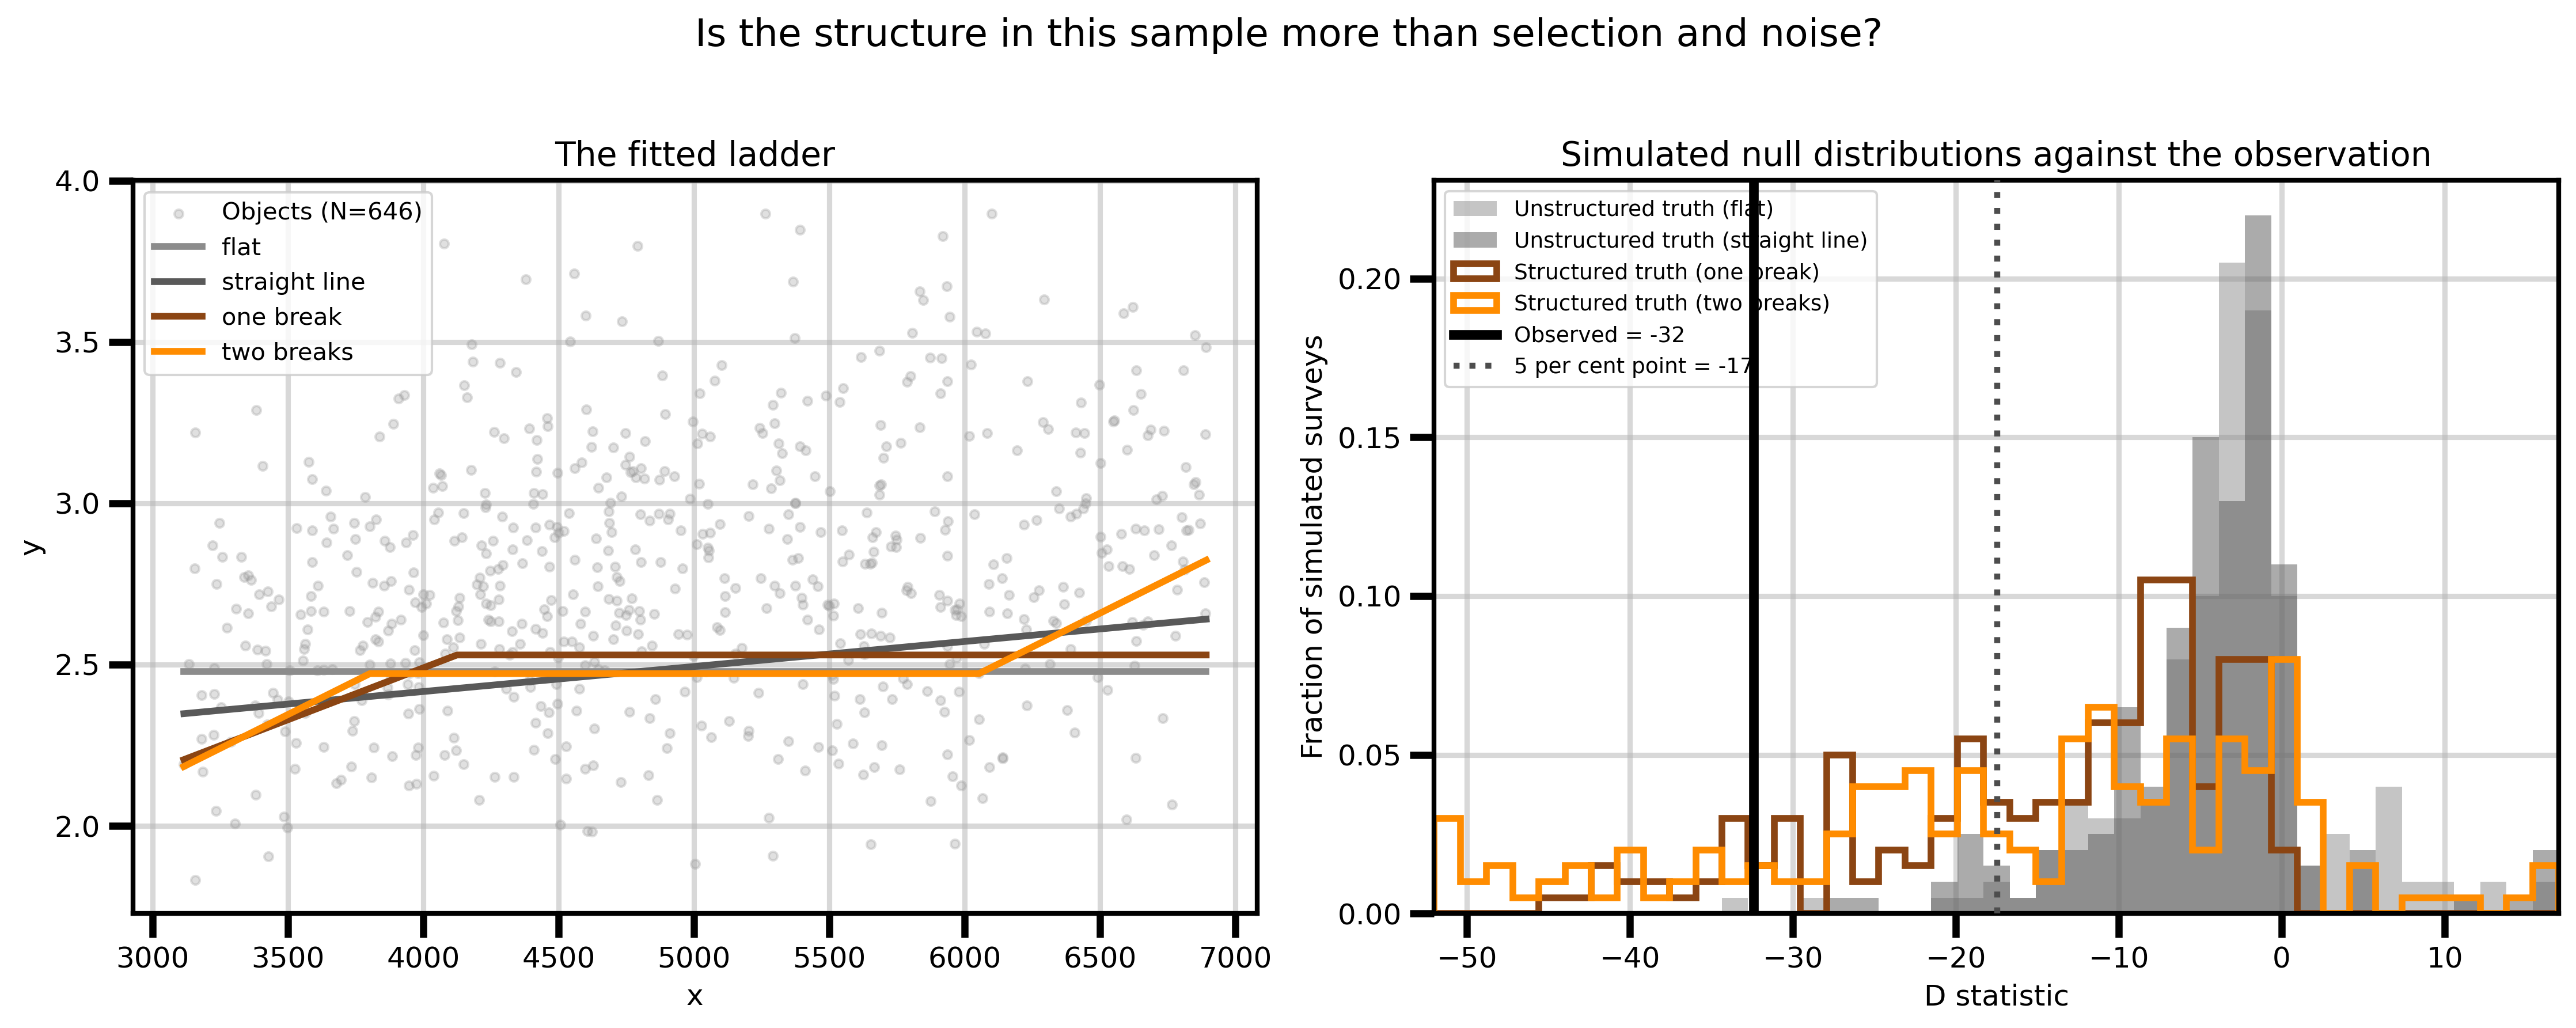

In [7]:
#### THE RESULT IN TWO PANELS ####

# Create the plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
# Individual objects as grey transparent dots
ax.scatter(x, y, s=13, color='0.6', alpha=0.3, zorder=2, label=f'Objects (N={n_objects})')
x_line = np.linspace(x_min, x_max, 600)
for name in models:
    ax.plot(x_line, models[name]['func'](x_line, *ladder[name]['params']),
            color=models[name]['color'], linewidth=2.8, zorder=3, label=name)
ax.set_xlabel('x', size=12)
ax.set_ylabel('y', size=12)
ax.set_title('The fitted ladder', size=14)
ax.legend(loc='upper left', fontsize=10)

ax = axes[1]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
everything = np.concatenate([simulated_d[name] for name in truths])
low, high = np.floor(np.percentile(everything, 0.5)), np.ceil(np.percentile(everything, 99.5))
edges = np.linspace(low, high, 44)
for name in truths:
    values = simulated_d[name]
    if truths[name]['family'] == 'simple':
        ax.hist(np.clip(values, low, high), bins=edges, alpha=0.5,
                color=truths[name]['color'],
                weights=np.full(len(values), 1 / len(values)),
                label=f'Unstructured truth ({name})')
    else:
        ax.hist(np.clip(values, low, high), bins=edges, histtype='step', linewidth=2.8,
                color=truths[name]['color'],
                weights=np.full(len(values), 1 / len(values)),
                label=f'Structured truth ({name})')
ax.axvline(observed_d, color='black', linewidth=4, zorder=6,
           label=f'Observed = {observed_d:.0f}')
ax.axvline(threshold, color='0.3', linestyle=':', linewidth=2.5, zorder=5,
           label=f'5 per cent point = {threshold:.0f}')
ax.set_xlabel('D statistic', size=12)
ax.set_ylabel('Fraction of simulated surveys', size=12)
ax.set_xlim(low, high)
ax.set_title('Simulated null distributions against the observation', size=14)
ax.legend(loc='upper left', fontsize=9)

for ax in axes:
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

fig.suptitle('Is the structure in this sample more than selection and noise?', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

fig.savefig('structure_null_test.png', dpi=300, bbox_inches='tight')

## Adapting this to your own sample

**Seed every generator.** `np.random.default_rng(11)` appears in every simulation cell
above. Unseeded resampling once made two cells fitting identical data appear to
disagree — the medians matched and only the error bars moved, which took a while to
diagnose.

**Give each new model several starting guesses.** The check loss is piecewise linear and
its surface is multi-modal in any breakpoint, so a single start lands in whichever basin
it happens to begin in. The `guesses` list in the models dict is what handles this.

**Watch for breakpoints collapsing onto the edge of your range.** If a fitted breakpoint
sits at `x_min` or `x_max`, the model has no plateau left and has quietly become a
simpler shape. That is informative — it means the data refuse that shape — but it is not
a fit, and reporting its parameters as though it were would mislead. Check with a profile:
force the breakpoint to a grid of fixed positions and look at the loss at each.

**Check your effective sample size before trusting a region.** Step 1 prints this per
region. A region whose `n_eff` is a fraction of its object count is being carried by a
few heavily weighted objects, and conclusions drawn there are fragile.

**D compares families, not members within a family.** It will tell you that structure
beats no structure. It will *not* reliably tell you which structured shape is right, or
where the structure sits. Two different structured truths can produce similarly extreme
D at similar rates. For that question use the loss directly, or look at where the
unstructured model fails region by region.

**Report the power alongside the p-value.** A p-value says the null is unlikely. The
power says whether your survey could have found the effect at all. Both belong in the
paper.

## References

- Koenker & Bassett 1978, *Econometrica* **46**, 33 — quantile regression
- Wilks 1938, *Ann. Math. Stat.* **9**, 60 — the likelihood ratio statistic and the factor of 2
- Davies 1977, *Biometrika* **64**, 247; 1987, *Biometrika* **74**, 33 — a nuisance parameter unidentified under the null
- Protassov et al. 2002, *ApJ* **571**, 545 — calibrating a likelihood ratio by simulation in an astronomical setting
- Kish 1965, *Survey Sampling* — effective sample size under weighting